<a href="https://colab.research.google.com/github/buntyedutainer/allocation-optimizer/blob/main/Day01_Allocation_Basics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import math
from itertools import permutations
import pandas as pd
import matplotlib.pyplot as plt

scores = pd.DataFrame(
    [[9, 8, 3, 1],
     [9, 2, 1, 1],
     [8, 7, 6, 2],
     [7, 6, 5, 4]],
    index=["Asha", "Ben", "Chitra", "Dev"],
    columns=["P1", "P2", "P3", "P4"])
scores

,P1,P2,P3,P4
Asha,9,8,3,1
Ben,9,2,1,1
Chitra,8,7,6,2
Dev,7,6,5,4


In [2]:
def greedy(scores, order):
    taken, result = set(), {}
    for student in order:
        free = scores.loc[student].drop(labels=list(taken))   # projects nobody has taken yet
        choice = free.idxmax()                                 # the free project this student likes most
        result[student] = choice
        taken.add(choice)
    return result

def total(scores, assignment):
    return sum(scores.loc[s, p] for s, p in assignment.items())

g = greedy(scores, ["Asha", "Ben", "Chitra", "Dev"])
print("Greedy assignment:", g)
print("Total happiness:", total(scores, g))

Greedy assignment: {'Asha': 'P1', 'Ben': 'P2', 'Chitra': 'P3', 'Dev': 'P4'}
Total happiness: 21


In [3]:
best_total, best_assign = -1, None
for perm in permutations(scores.columns):
    assignment = dict(zip(scores.index, perm))        # one way of handing out the projects
    t = total(scores, assignment)
    if t > best_total:
        best_total, best_assign = t, assignment

print("Best assignment:", best_assign)
print("Best total happiness:", best_total)

Best assignment: {'Asha': 'P2', 'Ben': 'P1', 'Chitra': 'P3', 'Dev': 'P4'}
Best total happiness: 27


       greedy project  greedy score best project  best score
Asha               P1             9           P2           8
Ben                P2             2           P1           9
Chitra             P3             6           P3           6
Dev                P4             4           P4           4


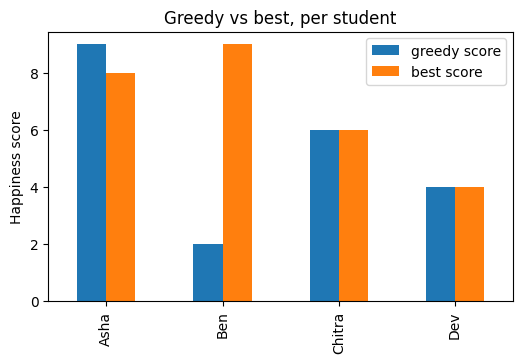

In [4]:
compare = pd.DataFrame({
    "greedy project": g,
    "greedy score": pd.Series({s: scores.loc[s, p] for s, p in g.items()}),
    "best project": best_assign,
    "best score": pd.Series({s: scores.loc[s, p] for s, p in best_assign.items()}),
})
print(compare)

compare[["greedy score", "best score"]].plot(kind="bar", figsize=(6, 3.5))
plt.ylabel("Happiness score")
plt.title("Greedy vs best, per student")
plt.show()

In [5]:
orders = list(permutations(scores.index))
totals = [total(scores, greedy(scores, o)) for o in orders]

print("Number of orders:", len(orders))
print("Lowest total:", min(totals), "| highest:", max(totals), "| average:", round(sum(totals) / len(totals), 1))
print("Orders that reach the best total", best_total, ":", sum(t == best_total for t in totals))
print("\nHow often each total occurs:")
print(pd.Series(totals).value_counts().sort_index())

Number of orders: 24
Lowest total: 14 | highest: 27 | average: 19.8
Orders that reach the best total 27 : 1

How often each total occurs:
14    1
16    4
17    1
18    5
20    1
21    3
22    6
23    1
24    1
27    1
Name: count, dtype: int64


In [6]:
for n in [4, 6, 8, 10, 12, 20]:
    print(f"{n:2d} students -> {math.factorial(n):,} ways to hand out the projects")

 4 students -> 24 ways to hand out the projects
 6 students -> 720 ways to hand out the projects
 8 students -> 40,320 ways to hand out the projects
10 students -> 3,628,800 ways to hand out the projects
12 students -> 479,001,600 ways to hand out the projects
20 students -> 2,432,902,008,176,640,000 ways to hand out the projects
